# 07 – Genre and juvenile-marker classification: small neural networks, compared with the classical results

Phase 2 of the popularity project (the popularity notebooks are unchanged). Data: `data/popularity_training_clean.csv` (17,727 items; no scraping). Two tasks, each **without** and **with** the description text:

1. **Genre** – science fiction / fantasy / mystery-thriller. Main experiment on the **clearly single-genre** records only (exactly one genre flag; 16,515 items). Genre labels are rule-based from subject tags, so they are a catalogue label, not a verdict by a reader.
2. **Juvenile marker** – `juvenile = 1` when a subject tag marks the item as juvenile. **`juvenile = 0` only means the catalogue lacks that marker; it does not mean the book is definitely for adults.** The classes are uneven (about 27 % marked), so besides accuracy and macro-F1 we report balanced accuracy and juvenile-class precision / recall / F1 (and ROC-AUC).

**Variant A** = metadata: title words (TF-IDF), creators (one-hot), publication year, scanned pages, archive age, number of creators and number of title words. **Variant B** = exactly the same, plus the description text (nothing else differs).

**Leakage rule.** Both labels are derived from subject tags, so *no subject-derived column is a model input*: not the subject tags, their count, the genre flags, `genre_primary`, `juvenile`, `sampling_stratum` or the collection flag. IDs and provenance fields are excluded too. The `Features` class refuses any column outside the allowed list (checked in the cell below). Genre and juvenile are related in the catalogue (fantasy items carry the marker more often); that relationship is *not* given to the models.

**Protocol.** One saved grouped split per task (group = `ol_group`; 5 grouped, stratified CV folds on 80 % of the work groups; the other 20 % locked as the test set). Thresholds, scalers, TF-IDF, SVD and early stopping use training rows only. Models are chosen with CV macro-F1 and the choice is written to disk **before** the test set is scored. Juvenile models use balanced class weights; no decision threshold is tuned. This notebook: a small MLP, compared with the classical results saved by notebook 06.

In [1]:
import json, time, warnings, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))
import phase2_experiment as p2
FAMILY = "neural"
P = p2.OUT; P.mkdir(parents=True, exist_ok=True); FIG = P / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 230, "display.max_columns", 40, "display.max_colwidth", 60, "display.max_rows", 200)
env = p2.environment(); (P / "environment_phase2.json").write_text(json.dumps(env, indent=2), encoding="utf-8")
print(json.dumps({k: env[k] for k in ("python", "scikit-learn", "torch", "numpy", "pandas", "device", "cpu_count", "seed", "mlp_seeds")}))
TASKS = ["genre", "juvenile"]

{"python": "3.13.2", "scikit-learn": "1.6.1", "torch": "2.14.0+cpu", "numpy": "2.2.3", "pandas": "2.2.3", "device": "cpu", "cpu_count": 16, "seed": 2026, "mlp_seeds": [2026, 2027, 2028]}


## 1. Eligible books and the leakage guard

In [2]:
df = p2.load_cohort()
D = {t: p2.task_frame(df, t) for t in TASKS}
for t in TASKS:
    c = np.bincount(D[t].y, minlength=len(p2.TASKS[t]["classes"]))
    print(f"{t}: {len(D[t]):,} items, {D[t].ol_group.nunique():,} works; class counts {dict(zip(p2.TASKS[t]['classes'], c.tolist()))}; majority-class share {c.max()/c.sum():.3f}")
multi = df[["genre_science_fiction", "genre_fantasy", "genre_mystery_thriller"]].sum(1)
print("genre flags per item in the full cohort (0 / 1 / 2 / 3 flags):", multi.value_counts().sort_index().to_dict(), "-> only the 1-flag records are used for genre")
print("\nMODEL INPUTS  :", p2.ALLOWED_COLS)
print("NEVER INPUTS  :", p2.EXCLUDED)
sample = p2.allowed(D["genre"].head(50)); assert set(sample.columns) == set(p2.ALLOWED_COLS) and not (set(p2.EXCLUDED) & set(sample.columns))
for w in ("juvenile",):
    print(f"\nthe word '{w}' appears in {int(df.title_text.str.contains(w).sum())} titles and {int(df.description.str.lower().str.contains(w).sum())} descriptions (of 17,727): no catalogue marker leaks through the text.")

genre: 16,515 items, 15,555 works; class counts {'science_fiction': 4748, 'fantasy': 5888, 'mystery_thriller': 5879}; majority-class share 0.357
juvenile: 17,727 items, 16,666 works; class counts {'no_marker': 12855, 'juvenile_marker': 4872}; majority-class share 0.725
genre flags per item in the full cohort (0 / 1 / 2 / 3 flags): {0: 40, 1: 16515, 2: 1127, 3: 45} -> only the 1-flag records are used for genre

MODEL INPUTS  : ['publication_year', 'log_pages', 'age_years', 'n_creators', 'title_words', 'title_text', 'creator_tokens', 'description']
NEVER INPUTS  : ['subjects', 'n_subjects', 'juvenile', 'genre_primary', 'genre_science_fiction', 'genre_fantasy', 'genre_mystery_thriller', 'sampling_stratum', 'in_americana', 'source_batch', 'identifier', 'ol_group', 'work_group', 'views_all_time', 'description_words']

the word 'juvenile' appears in 0 titles and 27 descriptions (of 17,727): no catalogue marker leaks through the text.


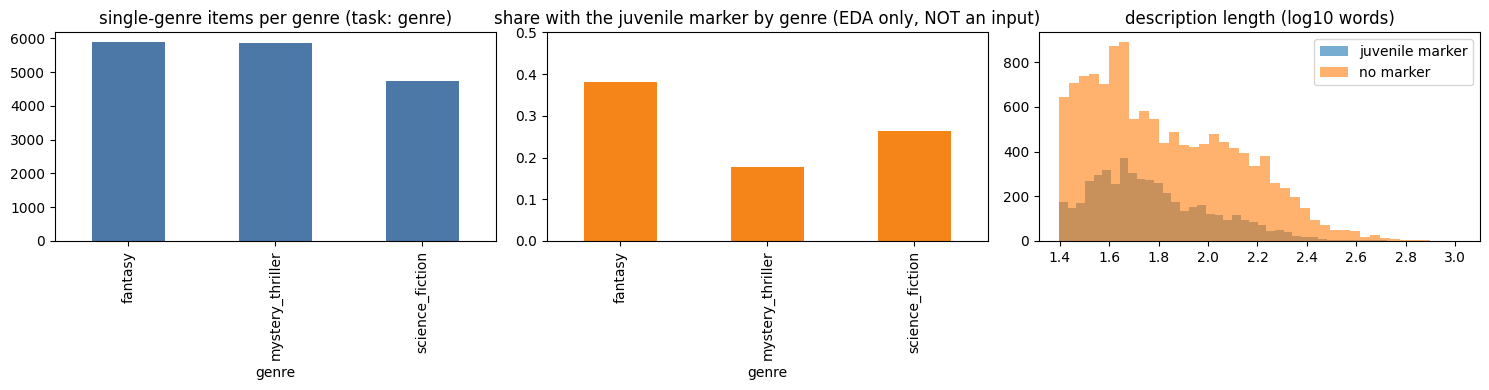

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
g = D["genre"]; g.assign(genre=[p2.GENRES[i] for i in g.y]).genre.value_counts().plot.bar(ax=ax[0], color="#4c78a8"); ax[0].set(title="single-genre items per genre (task: genre)")
jt = df.assign(genre=np.select([df.genre_science_fiction == 1, df.genre_fantasy == 1, df.genre_mystery_thriller == 1], p2.GENRES, "none")).query("genre != 'none'").groupby("genre").juvenile.mean()
jt.plot.bar(ax=ax[1], color="#f58518"); ax[1].set(title="share with the juvenile marker by genre (EDA only, NOT an input)", ylim=(0, .5))
for lab, s in (("juvenile marker", df[df.juvenile == 1]), ("no marker", df[df.juvenile == 0])):
    ax[2].hist(np.log10(s.description_words.clip(lower=1)), bins=40, alpha=.6, label=lab)
ax[2].set(title="description length (log10 words)"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG / f"phase2_eda.png", dpi=130); plt.show()

## 2. Saved grouped splits (written before any model is fitted)

In [4]:
# notebook 06 creates the splits; this notebook only loads them and checks their hashes, so both notebooks use identical books and folds
MAN = {}
for t in TASKS:
    MAN[t] = p2.build_split(t, D[t], force=False)
    meta = json.loads((P / f"split_{t}_meta.json").read_text(encoding="utf-8"))
    assert meta["sha256"] == p2.sha256_file(P / f"split_{t}.csv"), "split file changed after notebook 06"

In [5]:
for t in TASKS:
    m = MAN[t].copy(); m["label"] = [p2.TASKS[t]["classes"][i] for i in m.y]
    print(f"--- {t}: split sizes (rows / works), class counts"); display(pd.concat([m.groupby("split").agg(rows=("identifier", "size"), works=("ol_group", "nunique")), pd.crosstab(m.split, m.label)], axis=1))
    assert not (set(m[m.split == "test"].ol_group) & set(m[m.split == "pool"].ol_group))
    print(pd.crosstab(m[m.split == "pool"].cv_fold, m[m.split == "pool"].label).to_string())

--- genre: split sizes (rows / works), class counts


,rows,works,fantasy,mystery_thriller,science_fiction
split,,,,,
pool,13226,12443,4710,4688,3828
test,3289,3112,1178,1191,920


label    fantasy  mystery_thriller  science_fiction
cv_fold                                            
0            968               918              768
1            912               965              756
2            958               909              772
3            957               951              747
4            915               945              785
--- juvenile: split sizes (rows / works), class counts


,rows,works,juvenile_marker,no_marker
split,,,,
pool,14182,13329,3888,10294
test,3545,3337,984,2561


label    juvenile_marker  no_marker
cv_fold                            
0                    808       2033
1                    752       2093
2                    748       2083
3                    775       2065
4                    805       2020


## 3. Grouped cross-validation on the training pool

In [6]:
CV, SUM = {}, {}
for t in TASKS:
    t0 = time.time(); CV[t] = p2.run_cv(t, D[t], MAN[t], FAMILY, n_jobs=5, force=True)
    res = CV[t]["results"]; res.round(5).to_csv(P / f"{t}_{FAMILY}_cv_all_folds.csv", index=False)
    SUM[t] = p2.summarise_cv(res); SUM[t].round(5).to_csv(P / f"{t}_{FAMILY}_cv_summary.csv", index=False)
    print(f"{t}: cross-validation done in {time.time() - t0:.0f} s (mlp)")

genre: cross-validation done in 126 s (mlp)
juvenile: cross-validation done in 77 s (mlp)


In [7]:
for t in TASKS:
    s = SUM[t].copy(); s["setting"] = s.algo + " " + s.cfg_id.astype(str)
    vals = ["accuracy", "macro_f1"] + (["balanced_accuracy", "juv_f1"] if t == "juvenile" else [])
    print(f"=== {t}: CV mean over 5 grouped folds"); display(s.pivot(index="setting", columns="variant", values=vals).round(4))

=== genre: CV mean over 5 grouped folds


accuracy         macro_f1        
variant        A       B        A       B
setting                                  
mlp 0     0.6130  0.8237   0.6085  0.8203
mlp 1     0.6151  0.8253   0.6103  0.8219
mlp 2     0.6166  0.8237   0.6134  0.8204
mlp 3     0.6239  0.8263   0.6196  0.8234

=== juvenile: CV mean over 5 grouped folds


accuracy         macro_f1         balanced_accuracy          juv_f1        
variant        A       B        A       B                 A       B       A       B
setting                                                                            
mlp 0     0.6759  0.7771   0.6515  0.7455            0.6993  0.7766  0.5595  0.6558
mlp 1     0.6729  0.7784   0.6491  0.7467            0.6978  0.7775  0.5579  0.6572
mlp 2     0.6649  0.7734   0.6443  0.7426            0.6992  0.7757  0.5589  0.6537
mlp 3     0.6706  0.7753   0.6484  0.7446            0.7004  0.7776  0.5605  0.6561

### Model choice from CV only
Best configuration of each algorithm per variant by CV macro-F1; the selection is saved now, **before the test set is touched**.

In [8]:
SEL = {}
for t in TASKS:
    SEL[t] = p2.select_models(SUM[t]); SEL[t].round(5).to_csv(P / f"{t}_{FAMILY}_cv_selection.csv", index=False)
(P / f"selection_{FAMILY}_written_utc.txt").write_text(pd.Timestamp.utcnow().isoformat())
for t in TASKS:
    print("===", t); display(SEL[t][["variant", "algo", "family", "cfg", "cv_macro_f1", "cv_accuracy", "is_best_in_family"]].round(4))

=== genre


,variant,algo,family,cfg,cv_macro_f1,cv_accuracy,is_best_in_family
0,A,mlp,neural,"{""hidden"": [128, 64], ""weight_decay"": 0.01, ""dropout"": 0.3}",0.6196,0.6239,True
1,B,mlp,neural,"{""hidden"": [128, 64], ""weight_decay"": 0.01, ""dropout"": 0.3}",0.8234,0.8263,True


=== juvenile


,variant,algo,family,cfg,cv_macro_f1,cv_accuracy,is_best_in_family
0,A,mlp,neural,"{""hidden"": [64], ""weight_decay"": 0.001, ""dropout"": 0.1}",0.6515,0.6759,True
1,B,mlp,neural,"{""hidden"": [64], ""weight_decay"": 0.01, ""dropout"": 0.3}",0.7467,0.7784,True


In [9]:
rows = []
for t in TASKS:
    r = CV[t]["results"]; r = r[r.seed.astype(str).isin(["single", "avg"])]
    for s in SEL[t].itertuples():
        pass
    for a in SEL[t].algo.unique():
        ca = int(SEL[t][(SEL[t].variant == "A") & (SEL[t].algo == a)].cfg_id.iloc[0]); cb = int(SEL[t][(SEL[t].variant == "B") & (SEL[t].algo == a)].cfg_id.iloc[0])
        ra = r[(r.variant == "A") & (r.algo == a) & (r.cfg_id == ca)].sort_values("fold"); rb = r[(r.variant == "B") & (r.algo == a) & (r.cfg_id == cb)].sort_values("fold")
        for c in ["accuracy", "macro_f1"] + (["balanced_accuracy", "juv_f1"] if t == "juvenile" else []):
            d = rb[c].to_numpy() - ra[c].to_numpy()
            rows.append({"task": t, "algo": a, "metric": c, "A_mean": ra[c].mean(), "B_mean": rb[c].mean(), "mean_B_minus_A": d.mean(), "sd_of_fold_differences": d.std(ddof=1), "folds_B_better": int((d > 0).sum())})
PC = pd.DataFrame(rows); PC.round(4).to_csv(P / f"cv_paired_A_vs_B_{FAMILY}.csv", index=False)
print("Description effect inside CV (B minus A, same algorithm, same five folds)"); display(PC.round(4))

Description effect inside CV (B minus A, same algorithm, same five folds)


,task,algo,metric,A_mean,B_mean,mean_B_minus_A,sd_of_fold_differences,folds_B_better
0,genre,mlp,accuracy,0.6239,0.8263,0.2025,0.0116,5
1,genre,mlp,macro_f1,0.6196,0.8234,0.2038,0.0118,5
2,juvenile,mlp,accuracy,0.6759,0.7784,0.1025,0.0086,5
3,juvenile,mlp,macro_f1,0.6515,0.7467,0.0952,0.0058,5
4,juvenile,mlp,balanced_accuracy,0.6993,0.7775,0.0783,0.0058,5
5,juvenile,mlp,juv_f1,0.5595,0.6572,0.0977,0.0070,5


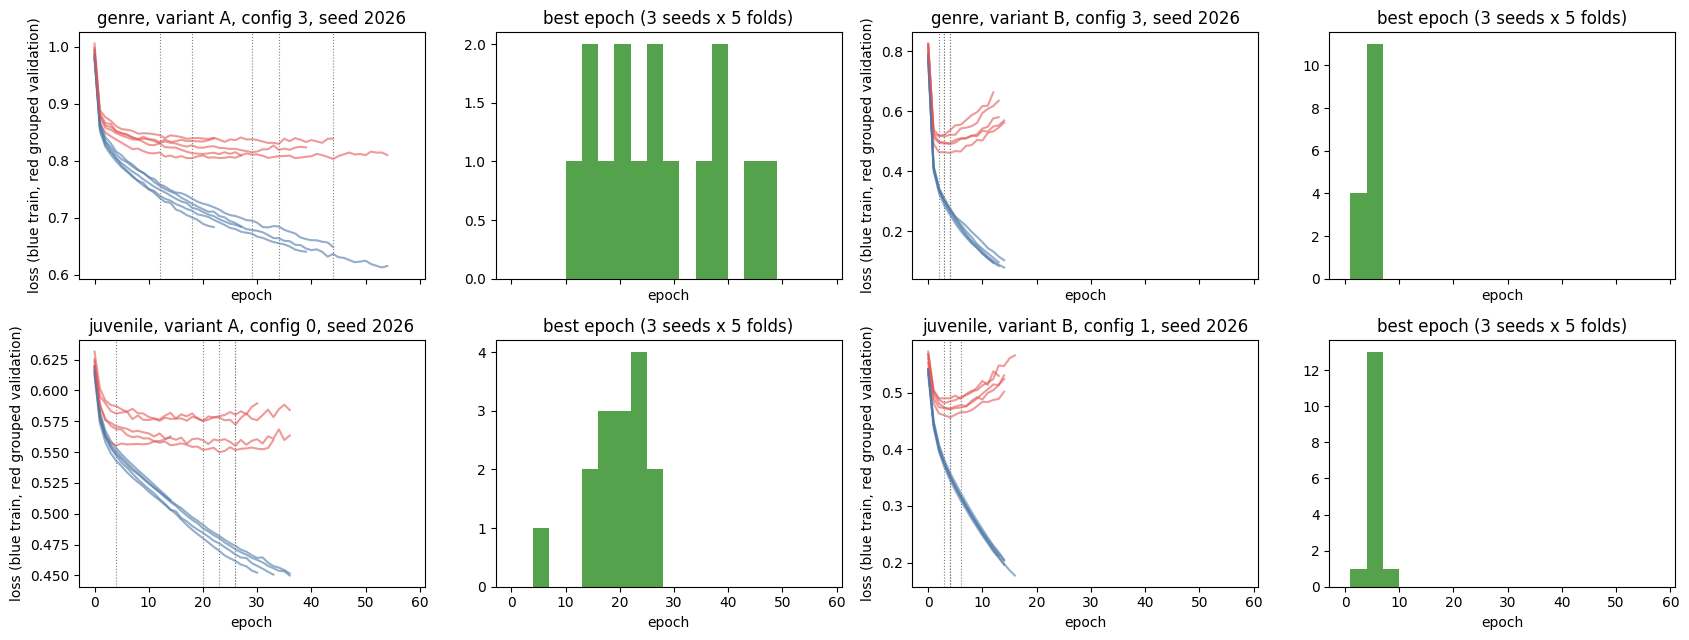

In [10]:
fig, ax = plt.subplots(2, 4, figsize=(17, 6.5), sharex=True)
for i, t in enumerate(TASKS):
    for j, v in enumerate(["A", "B"]):
        for jj, which in enumerate(["train_loss", "val_loss"]):
            pass
        a = ax[i, j * 2 + 0]; b = ax[i, j * 2 + 1]
        cid = int(SEL[t][(SEL[t].variant == v) & (SEL[t].algo == "mlp")].cfg_id.iloc[0])
        for k in range(p2.N_FOLDS):
            h = CV[t]["hist"][(v, "mlp", cid, "2026", k)]
            a.plot(h["train_loss"], color="#4c78a8", alpha=.6); a.plot(h["val_loss"], color="#e45756", alpha=.6); a.axvline(h["best_epoch"] - 1, color="grey", ls=":", lw=.8)
        a.set(title=f"{t}, variant {v}, config {cid}, seed 2026", xlabel="epoch", ylabel="loss (blue train, red grouped validation)")
        eb = pd.Series([CV[t]["hist"][(v, "mlp", cid, str(s), k)]["best_epoch"] for s in p2.MLP_SEEDS for k in range(p2.N_FOLDS)])
        b.hist(eb, bins=range(1, 60, 3), color="#54a24b"); b.set(title="best epoch (3 seeds x 5 folds)", xlabel="epoch")
plt.tight_layout(); plt.savefig(FIG / "phase2_mlp_loss_curves.png", dpi=130); plt.show()

## 4. Locked test set (selected configurations refit on the whole training pool)

In [11]:
TEST, TT = {}, {}
for t in TASKS:
    t0 = time.time(); TEST[t] = p2.run_test(t, D[t], MAN[t], SEL[t], FAMILY, force=True); TT[t] = p2.test_tables(t, TEST[t], SEL[t])
    TT[t]["table"].round(5).to_csv(P / f"{t}_{FAMILY}_test_results.csv", index=False); TT[t]["confusion"].to_csv(P / f"{t}_{FAMILY}_test_confusion.csv", index=False)
    if len(TT[t]["seeds"]): TT[t]["seeds"].round(5).to_csv(P / f"{t}_{FAMILY}_test_seed_variability.csv", index=False)
    p2.predictions_frame(t, TEST[t], TT[t]["scores"], D[t]).to_csv(P / f"{t}_{FAMILY}_test_predictions.csv", index=False)
    np.savez_compressed(P / f"{t}_{FAMILY}_test_scores.npz", ids=np.array(TEST[t]["test_identifiers"]), **{f"{v}__{a}": s for (v, a), s in TT[t]["scores"].items()})
    print(f"{t}: test done in {time.time() - t0:.0f} s; train pool {TEST[t]['pool_rows']:,} / test {TEST[t]['test_rows']:,} items; class counts in test {np.bincount(TEST[t]['test_y']).tolist()}")

genre: test done in 37 s; train pool 13,226 / test 3,289 items; class counts in test [920, 1178, 1191]
juvenile: test done in 22 s; train pool 14,182 / test 3,545 items; class counts in test [2561, 984]


In [12]:
for t in TASKS:
    tab = TT[t]["table"]; cols = ["accuracy", "macro_f1"] + (["balanced_accuracy", "juv_precision", "juv_recall", "juv_f1", "roc_auc"] if t == "juvenile" else [f"f1_{g}" for g in p2.GENRES])
    print(f"=== TEST {t}: dummy = train-fitted baseline (always the most common training class)")
    display(tab.pivot(index="algo", columns="variant", values=cols).round(4))
    print("CV-chosen best in this family per variant:"); display(tab[tab.is_best_in_family][["variant", "algo", "cfg", "accuracy", "macro_f1"]].round(4))

=== TEST genre: dummy = train-fitted baseline (always the most common training class)


accuracy         macro_f1         f1_science_fiction         f1_fantasy         f1_mystery_thriller        
variant        A       B        A       B                  A       B          A       B                   A       B
algo                                                                                                               
mlp        0.612  0.8121   0.6043  0.8065             0.5384  0.7521     0.6095  0.7958              0.6651  0.8716

CV-chosen best in this family per variant:


,variant,algo,cfg,accuracy,macro_f1
0,A,mlp,"{""hidden"": [128, 64], ""weight_decay"": 0.01, ""dropout"": 0.3}",0.6120,0.6043
1,B,mlp,"{""hidden"": [128, 64], ""weight_decay"": 0.01, ""dropout"": 0.3}",0.8121,0.8065


=== TEST juvenile: dummy = train-fitted baseline (always the most common training class)


accuracy         macro_f1         balanced_accuracy         juv_precision         juv_recall         juv_f1         roc_auc        
variant        A       B        A       B                 A       B             A       B          A       B      A       B       A       B
algo                                                                                                                                       
mlp       0.6863  0.7941   0.6619  0.7655            0.7066  0.7965        0.4602  0.5959      0.752  0.8018  0.571  0.6837  0.7759  0.8731

CV-chosen best in this family per variant:


,variant,algo,cfg,accuracy,macro_f1
0,A,mlp,"{""hidden"": [64], ""weight_decay"": 0.001, ""dropout"": 0.1}",0.6863,0.6619
1,B,mlp,"{""hidden"": [64], ""weight_decay"": 0.01, ""dropout"": 0.3}",0.7941,0.7655


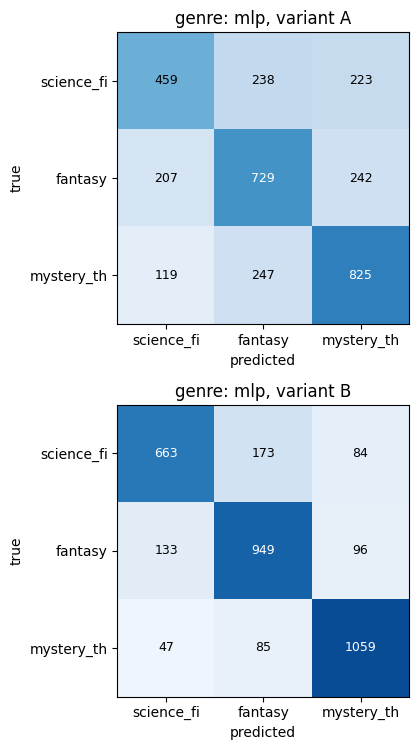

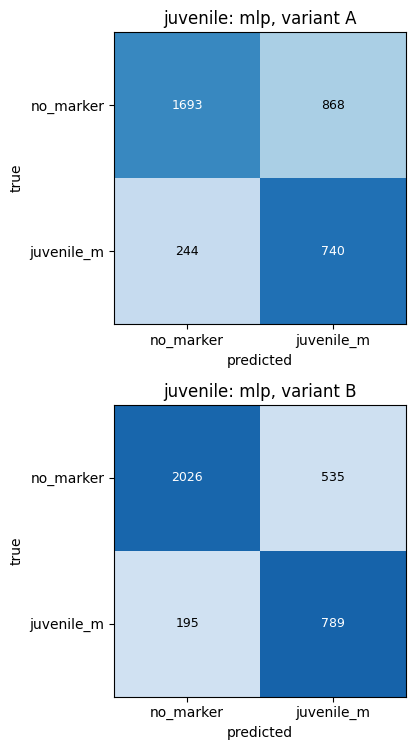

In [13]:
cm = {t: TT[t]["confusion"] for t in TASKS}
shown = [a for a in (["dummy", "logreg", "linsvc", "hgb"] if FAMILY == "classical" else ["mlp"])]
for t in TASKS:
    K = len(p2.TASKS[t]["classes"]); cls = p2.TASKS[t]["classes"]
    fig, ax = plt.subplots(2, len(shown), figsize=(4.2 * len(shown), 7.6), squeeze=False)
    for i, v in enumerate(p2.VARIANTS):
        for j, a in enumerate(shown):
            x = cm[t][(cm[t].variant == v) & (cm[t].algo == a)].set_index("true_class").loc[cls][[f"pred_{c}" for c in cls]].to_numpy()
            ax[i, j].imshow(x / x.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
            for p in range(K):
                for q in range(K): ax[i, j].text(q, p, str(x[p, q]), ha="center", va="center", color="black" if x[p, q] / x[p].sum() < .6 else "white", fontsize=9)
            ax[i, j].set(xticks=range(K), yticks=range(K), xticklabels=[c[:10] for c in cls], yticklabels=[c[:10] for c in cls], title=f"{t}: {a}, variant {v}", xlabel="predicted", ylabel="true")
    plt.tight_layout(); plt.savefig(FIG / f"phase2_confusion_{t}_{FAMILY}.png", dpi=130); plt.show()

In [14]:
for t in TASKS:
    tab = TT[t]["table"]; ca = [c for c in tab.columns if "|" in c]
    print(f"=== {t}: does the result depend on author names? Test items whose creator also appears in the training pool: {TT[t]['n_author_seen']:,}; creator NOT seen: {TT[t]['n_author_unseen']:,}")
    display(tab[tab.is_best_in_family | (tab.algo == "dummy")][["variant", "algo", "accuracy", "macro_f1"] + ca].round(4))

=== genre: does the result depend on author names? Test items whose creator also appears in the training pool: 1,823; creator NOT seen: 1,466


,variant,algo,accuracy,macro_f1,accuracy | author seen in training,macro_f1 | author seen in training,accuracy | author NOT seen in training,macro_f1 | author NOT seen in training
0,A,mlp,0.6120,0.6043,0.6615,0.6581,0.5505,0.5322
1,B,mlp,0.8121,0.8065,0.8332,0.8321,0.7858,0.7704


=== juvenile: does the result depend on author names? Test items whose creator also appears in the training pool: 2,027; creator NOT seen: 1,518


,variant,algo,accuracy,macro_f1,accuracy | author seen in training,macro_f1 | author seen in training,accuracy | author NOT seen in training,macro_f1 | author NOT seen in training
0,A,mlp,0.6863,0.6619,0.7183,0.6932,0.6436,0.6207
1,B,mlp,0.7941,0.7655,0.7884,0.7644,0.8017,0.7663


### Is a difference reliable? Group-level bootstrap on the test set (1,000 resamples of work groups)
Same test items for A and B. Intervals that include 0 are not distinguishable from noise on this test set.

In [15]:
# classical results saved by notebook 06 (same books, same folds, same test set)
need = [P / f"{t}_classical_{x}" for t in TASKS for x in ("cv_summary.csv", "cv_selection.csv", "test_results.csv", "test_scores.npz", "test_predictions.csv")]
missing = [str(p.name) for p in need if not p.exists()]
assert not missing, f"run notebook 06 first; missing {missing}"
CSUM = {t: pd.read_csv(P / f"{t}_classical_cv_summary.csv") for t in TASKS}
CSEL = {t: pd.read_csv(P / f"{t}_classical_cv_selection.csv") for t in TASKS}
CTEST = {t: pd.read_csv(P / f"{t}_classical_test_results.csv") for t in TASKS}
CSC = {t: np.load(P / f"{t}_classical_test_scores.npz") for t in TASKS}
for t in TASKS:
    assert list(CSC[t]["ids"]) == TEST[t]["test_identifiers"], "test items differ from notebook 06"
BOOT = {}
for t in TASKS:
    y, g, sc = TEST[t]["test_y"], TEST[t]["test_groups"], TT[t]["scores"]
    pr = {("N", v): sc[(v, "mlp")].argmax(1) for v in p2.VARIANTS}
    cwin = {v: CSEL[t][(CSEL[t].variant == v) & CSEL[t].is_best_in_family].iloc[0].algo for v in p2.VARIANTS}
    for v in p2.VARIANTS:
        pr[("C", v)] = CSC[t][f"{v}__{cwin[v]}"].argmax(1); pr[("D", v)] = CSC[t][f"{v}__dummy"].argmax(1)
    pairs = [("description effect (B - A), neural network", "mlp", ("N", "A"), ("N", "B"))]
    for v in p2.VARIANTS:
        pairs.append((f"neural network minus best classical model chosen by CV, variant {v}", f"mlp - {cwin[v]}", ("C", v), ("N", v)))
        pairs.append((f"neural network minus train-fitted baseline, variant {v}", "mlp - dummy", ("D", v), ("N", v)))
    BOOT[t] = p2.bootstrap_comparisons(t, y, g, pr, pairs); BOOT[t].round(5).to_csv(P / f"{t}_neural_test_bootstrap.csv", index=False)
    keep = ["comparison", "detail", "accuracy_mean", "accuracy_lo95", "accuracy_hi95", "macro_f1_mean", "macro_f1_lo95", "macro_f1_hi95"] + (["balanced_accuracy_mean", "balanced_accuracy_lo95", "balanced_accuracy_hi95", "juv_f1_mean", "juv_f1_lo95", "juv_f1_hi95"] if t == "juvenile" else [])
    print("===", t, "(second minus first)"); display(BOOT[t][keep].round(4))

=== genre (second minus first)


,comparison,detail,accuracy_mean,accuracy_lo95,accuracy_hi95,macro_f1_mean,macro_f1_lo95,macro_f1_hi95
0,"description effect (B - A), neural network",mlp,0.1999,0.1819,0.2188,0.2021,0.1837,0.2218
1,"neural network minus best classical model chosen by CV, ...",mlp - logreg,-0.0961,-0.1125,-0.0802,-0.0979,-0.1148,-0.0817
2,"neural network minus train-fitted baseline, variant A",mlp - dummy,0.2538,0.2291,0.2778,0.4286,0.4108,0.4470
3,"neural network minus best classical model chosen by CV, ...",mlp - linsvc,-0.0505,-0.0630,-0.0380,-0.0530,-0.0655,-0.0400
4,"neural network minus train-fitted baseline, variant B",mlp - dummy,0.4537,0.4321,0.4754,0.6307,0.6156,0.6460


=== juvenile (second minus first)


,comparison,detail,accuracy_mean,accuracy_lo95,accuracy_hi95,macro_f1_mean,macro_f1_lo95,macro_f1_hi95,balanced_accuracy_mean,balanced_accuracy_lo95,balanced_accuracy_hi95,juv_f1_mean,juv_f1_lo95,juv_f1_hi95
0,"description effect (B - A), neural network",mlp,0.1075,0.0913,0.1238,0.1034,0.0870,0.1192,0.0897,0.0719,0.1057,0.1125,0.0914,0.1320
1,"neural network minus best classical model chosen by CV, ...",mlp - hgb,-0.0330,-0.0464,-0.0201,-0.0261,-0.0400,-0.0127,-0.0146,-0.0300,0.0004,-0.0183,-0.0358,-0.0014
2,"neural network minus train-fitted baseline, variant A",mlp - dummy,-0.0360,-0.0594,-0.0135,0.2426,0.2229,0.2608,0.2069,0.1898,0.2240,0.5711,0.5463,0.5939
3,"neural network minus best classical model chosen by CV, ...",mlp - hgb,-0.0312,-0.0427,-0.0192,-0.0267,-0.0390,-0.0127,-0.0112,-0.0247,0.0044,-0.0256,-0.0421,-0.0059
4,"neural network minus train-fitted baseline, variant B",mlp - dummy,0.0715,0.0524,0.0918,0.3460,0.3291,0.3637,0.2966,0.2813,0.3117,0.6836,0.6617,0.7057


In [16]:
rows = []
for t in TASKS:
    for v in p2.VARIANTS:
        c = CTEST[t][(CTEST[t].variant == v) & CTEST[t].is_best_in_family].iloc[0]; n = TT[t]["table"][(TT[t]["table"].variant == v) & (TT[t]["table"].algo == "mlp")].iloc[0]
        cvc = CSUM[t][(CSUM[t].variant == v) & (CSUM[t].algo == c.algo) & (CSUM[t].cfg_id == int(CSEL[t][(CSEL[t].variant == v) & (CSEL[t].algo == c.algo)].cfg_id.iloc[0]))].iloc[0]
        cvn = SEL[t][(SEL[t].variant == v) & (SEL[t].algo == "mlp")].iloc[0]
        row = {"task": t, "variant": v, "best classical (CV)": c.algo, "CV macro-F1 classical": cvc.macro_f1, "CV macro-F1 neural": cvn.cv_macro_f1,
               "CV winner": "neural" if cvn.cv_macro_f1 > cvc.macro_f1 else c.algo, "test acc classical": c.accuracy, "test acc neural": n.accuracy,
               "test macro-F1 classical": c.macro_f1, "test macro-F1 neural": n.macro_f1}
        if t == "juvenile":
            row.update({"test bal.acc classical": c.balanced_accuracy, "test bal.acc neural": n.balanced_accuracy, "test juv-F1 classical": c.juv_f1, "test juv-F1 neural": n.juv_f1})
        rows.append(row)
CMP = pd.DataFrame(rows); CMP.round(4).to_csv(P / "neural_vs_classical_summary.csv", index=False)
print("Neural network versus the best classical model (chosen by CV in notebook 06)"); display(CMP.round(4))

Neural network versus the best classical model (chosen by CV in notebook 06)


,task,variant,best classical (CV),CV macro-F1 classical,CV macro-F1 neural,CV winner,test acc classical,test acc neural,test macro-F1 classical,test macro-F1 neural,test bal.acc classical,test bal.acc neural,test juv-F1 classical,test juv-F1 neural
0,genre,A,logreg,0.6865,0.6196,logreg,0.7078,0.6120,0.7020,0.6043,NaN,NaN,NaN,NaN
1,genre,B,linsvc,0.8510,0.8234,linsvc,0.8626,0.8121,0.8595,0.8065,NaN,NaN,NaN,NaN
2,juvenile,A,hgb,0.6826,0.6515,hgb,0.7193,0.6863,0.6881,0.6619,0.7213,0.7066,0.5894,0.5710
3,juvenile,B,hgb,0.7760,0.7467,hgb,0.8254,0.7941,0.7924,0.7655,0.8078,0.7965,0.7095,0.6837


## 5. Grouped learning curves (training pool only; the test set is not used)

In [17]:
LC = {}
for t in TASKS:
    t0 = time.time(); LC[t] = p2.run_learning_curves(t, D[t], MAN[t], SEL[t], FAMILY, n_jobs=5, force=True); LC[t].round(5).to_csv(P / f"{t}_{FAMILY}_learning_curves.csv", index=False)
    print(f"{t}: learning curves done in {time.time() - t0:.0f} s")

LCC = {t: pd.read_csv(P / f"{t}_classical_learning_curves.csv") for t in TASKS}

genre: learning curves done in 54 s
juvenile: learning curves done in 43 s


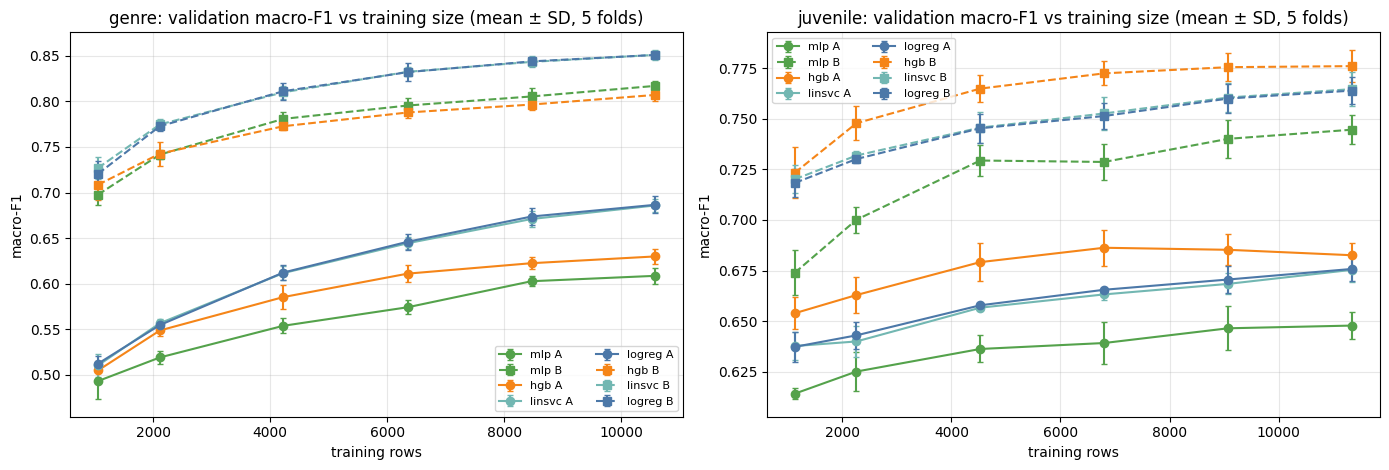

genre


rows                  macro_f1                
fraction           0.2     0.6      1.0      0.2     0.6     1.0
algo   variant                                                  
hgb    A        2113.0  6350.0  10580.8   0.5487  0.6110  0.6299
       B        2113.0  6350.0  10580.8   0.7426  0.7878  0.8071
linsvc A        2113.0  6350.0  10580.8   0.5566  0.6444  0.6858
       B        2113.0  6350.0  10580.8   0.7747  0.8324  0.8510
logreg A        2113.0  6350.0  10580.8   0.5546  0.6460  0.6865
       B        2113.0  6350.0  10580.8   0.7728  0.8321  0.8510
mlp    A        2113.0  6350.0  10580.8   0.5191  0.5741  0.6086
       B        2113.0  6350.0  10580.8   0.7416  0.7955  0.8170

juvenile


rows                  macro_f1                
fraction           0.2     0.6      1.0      0.2     0.6     1.0
algo   variant                                                  
hgb    A        2260.0  6800.4  11345.6   0.6629  0.6863  0.6826
       B        2260.0  6800.4  11345.6   0.7478  0.7725  0.7760
linsvc A        2260.0  6800.4  11345.6   0.6400  0.6632  0.6754
       B        2260.0  6800.4  11345.6   0.7319  0.7526  0.7647
logreg A        2260.0  6800.4  11345.6   0.6430  0.6655  0.6758
       B        2260.0  6800.4  11345.6   0.7301  0.7514  0.7640
mlp    A        2260.0  6800.4  11345.6   0.6251  0.6392  0.6478
       B        2260.0  6800.4  11345.6   0.7001  0.7287  0.7446

In [18]:
col = {"logreg": "#4c78a8", "linsvc": "#72b7b2", "hgb": "#f58518", "mlp": "#54a24b"}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for a, t in zip(ax, TASKS):
    frames = [LC[t]] + ([] if FAMILY == "classical" else [LCC[t]])
    for g_ in frames:
        for (v, algo), g in g_.groupby(["variant", "algo"]):
            s = g.groupby("fraction").agg(rows=("train_rows", "mean"), m=("macro_f1", "mean"), sd=("macro_f1", "std"))
            a.errorbar(s.rows, s.m, yerr=s.sd, color=col[algo], ls="-" if v == "A" else "--", marker="o" if v == "A" else "s", capsize=2, label=f"{algo} {v}")
    a.set(title=f"{t}: validation macro-F1 vs training size (mean ± SD, 5 folds)", xlabel="training rows", ylabel="macro-F1"); a.legend(ncol=2, fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / f"phase2_learning_curves_{FAMILY}.png", dpi=130); plt.show()
for t in TASKS:
    x = pd.concat([LC[t]] + ([] if FAMILY == "classical" else [LCC[t]]))
    print(t); display(x[x.fraction.isin([0.2, 0.6, 1.0])].groupby(["algo", "variant", "fraction"]).agg(rows=("train_rows", "mean"), macro_f1=("macro_f1", "mean")).round(4).unstack("fraction"))

## 6. Training times

In [19]:
tt = []
for t in TASKS:
    r = CV[t]["results"]; r = r[r.seed.astype(str).isin(["single", "avg"])].merge(SEL[t][["variant", "algo", "cfg_id"]], on=["variant", "algo", "cfg_id"])
    r = r.assign(per_seed=np.where(r.algo == "mlp", r.fit_seconds / len(p2.MLP_SEEDS), r.fit_seconds))
    x = r.groupby(["algo", "variant"]).agg(cv_fit_s_per_fold=("fit_seconds", "mean"), cv_fit_s_per_seed_or_model=("per_seed", "mean")).round(2)
    fin = TT[t]["table"].set_index(["algo", "variant"]).fit_seconds.round(2).rename("final_fit_s_on_pool")
    x = x.join(fin); x.insert(0, "task", t); tt.append(x.reset_index())
TT_ALL = pd.concat(tt); TT_ALL.to_csv(P / f"training_times_{FAMILY}.csv", index=False); display(TT_ALL)
print("Feature construction (TF-IDF/SVD/scaling for A and B together), seconds: genre/juvenile final fits %.1f / %.1f" % (TEST["genre"]["feature_seconds"], TEST["juvenile"]["feature_seconds"]))
print("MLP fit times in 'cv_fit_s_per_fold' are the sum over the three seeds; CPU only.")

,algo,variant,task,cv_fit_s_per_fold,cv_fit_s_per_seed_or_model,final_fit_s_on_pool
0,mlp,A,genre,18.51,6.17,22.48
1,mlp,B,genre,7.51,2.50,7.59
0,mlp,A,juvenile,7.74,2.58,8.95
1,mlp,B,juvenile,5.04,1.68,5.36


Feature construction (TF-IDF/SVD/scaling for A and B together), seconds: genre/juvenile final fits 7.0 / 7.7
MLP fit times in 'cv_fit_s_per_fold' are the sum over the three seeds; CPU only.


## 7. Findings

All numbers are from this executed notebook; same books, folds and test sets as notebook 06. The MLP (ReLU, AdamW, grouped early stopping, three predeclared seeds averaged) was chosen by CV: genre – two hidden layers (128, 64), weight decay 0.01, dropout 0.3, in both variants; juvenile – one hidden layer of 64 (A: weight decay 0.001, dropout 0.1; B: 0.01 / 0.3).

| Test set | Best classical (CV, notebook 06) | **Neural network** |
|---|---|---|
| Genre A: accuracy / macro-F1 | 70.8 % / 0.702 (LogReg) | 61.2 % / 0.604 |
| Genre B: accuracy / macro-F1 | 86.3 % / 0.860 (LinearSVC) | 81.2 % / 0.807 |
| Juvenile A: accuracy / macro-F1 / balanced acc. / marker F1 | 71.9 % / 0.688 / 0.721 / 0.589 (HGB) | 68.6 % / 0.662 / 0.707 / 0.571 |
| Juvenile B: accuracy / macro-F1 / balanced acc. / marker F1 | 82.5 % / 0.792 / 0.808 / 0.710 (HGB) | 79.4 % / 0.766 / 0.797 / 0.684 |
| Juvenile B: marker precision / recall / ROC-AUC | 0.659 / 0.768 / 0.896 | 0.596 / 0.802 / 0.873 |

**Do descriptions help the neural network? Yes, as with the classical models.** Genre +20.0 accuracy points (95 % interval +18.2 to +21.9), juvenile +10.8 points (+9.1 to +12.4), juvenile-class F1 +0.113; B beat A in all 5 CV folds in both tasks.

**Does the neural network beat the classical models? No.** The CV chose a classical model in all four comparisons, and the test set agrees. Neural minus best classical: genre A −9.6 accuracy points (−11.3 to −8.0), genre B −5.1 (−6.3 to −3.8); juvenile A −3.3 points (−4.6 to −2.0) and B −3.1 (−4.3 to −1.9), macro-F1 −0.026 / −0.027. On balanced accuracy for juvenile the intervals include 0 (A −0.015, B −0.011), so there the network is roughly level in recall-weighted terms but less precise (marker F1 −0.018 / −0.026). The three seeds agree closely (genre B accuracy 80.4–81.0 %), so this is not a bad-seed effect.

**Why it is probably behind (not proven).** The network sees 100 + 200 SVD components, while the linear models see all the sparse TF-IDF words and creators; that compression loses detail. With the description the network also overfits very fast: its best epoch was 4 (genre B) and 5–7 (juvenile B), i.e. early stopping ends training almost immediately. The result applies to this small architecture, this input representation and this bounded search (four settings, three seeds); a larger search, a different text representation or a pretrained text model was not tried and could behave differently.

**Learning curves.** The network's genre B macro-F1 rises from 0.70 (10 % of the data) to 0.82 (100 %) and juvenile B from 0.67 to 0.745; the classical curves in the plot stay above them at every training size, so more data does not close the gap here.

**Training time.** 1.7 s (juvenile B) to 6.2 s (genre A) per seed on CPU in CV (final fit on the pool, three seeds: 5–22 s); comparable to HGB and slower than LogReg, with no accuracy gain.

**Limits.** As in notebook 06: rule-based catalogue labels (`juvenile = 0` is "no marker"), automated description filter, one locked test set per task, author overlap (for the network, genre A accuracy drops from 66.2 % to 55.1 % on unseen creators), balanced class weights and default thresholds for juvenile.

## 8. Reproduce
```bash
pip install -r requirements-analysis.txt
cd notebooks
jupyter nbconvert --to notebook --execute --inplace 06_genre_juvenile_classical.ipynb    # first: creates the saved splits and classical results
jupyter nbconvert --to notebook --execute --inplace 07_genre_juvenile_neural.ipynb      # then this notebook, about 15-25 minutes
```
Seeds: split/CV 2026; MLP seeds 2026-2028 (predeclared). Outputs are in `report/ml/phase2/` (splits with hashes, CV, test, bootstrap, learning-curve, training-time tables and `figures/`).

## 9. Try a book: trained-on and not-trained-on, with and without description

Run the **Setup** cell once (it refits the CV-selected neural models on the saved training pools: no scraping, no CV rerun), then run any example. Each cell has the book's real details written in `BOOK`; edit them (or type your own book) and rerun that cell. Leave `description` empty to use only the **without-description** models; give a description to see **both** models side by side.

Every prediction shows the **genre** (science fiction / fantasy / mystery-thriller) and the **juvenile marker**. The catalogue labels under `CATALOGUE` come from the subject tags: they are only shown *after* the prediction and are never model inputs (neither are subjects, genre flags or the marker). `no marker` means the catalogue lacks the marker, not that a book is for adults. Two examples were in the training pools of both tasks; two are archive.org books that are in none of our datasets. Four books illustrate behaviour; the test-set tables above are the accuracy measurement.

**How these four books were chosen.** They are illustrations picked by hand, not a sample. Example 9.2 was first *Digital Fortress*, which the classical genre model got wrong (fantasy 43 % against mystery/thriller 27 %; the neural network got it right). It was replaced by *The ABC Murders* after trying 14 outside candidates without the description: the genre was right for 13 of 14 with the classical models (miss: Digital Fortress) and 13 of 14 with the neural networks (miss: Anansi Boys). For an honest picture, on **400 random outside single-genre books** (in none of our datasets; catalogue labels from subject tags; `report/ml/phase2/outside_random_check.csv`) genre accuracy was 76.0 % / 88.5 % (classical, without / with description) and 64.0 % / 84.0 % (neural), and juvenile balanced accuracy 0.78 / 0.84 (classical) and 0.72 / 0.80 (neural).

### Setup — run once

In [20]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import phase2_demo
book_predictor = phase2_demo.Phase2Predictor.from_project("neural")

Preparing the selected neural models once from the saved training pools (no scraping, no CV rerun) ...
Ready in 71 s. Edit BOOK and rerun only the Predict cell for each book.


### 9.1 Trained-on book, without description — Percy Jackson and the Sea of Monsters

[Open this archived item](https://archive.org/details/percyjacksonseao0000rior_x0q0). Catalogue labels: **fantasy**, juvenile marker **yes**. This book was in the training pool of both tasks. The description is left empty on purpose (the saved one has 79 words).

In [21]:
BOOK = {'title': 'Percy Jackson and the sea of monsters',
 'description': '',
 'author': 'Riordan, Rick',
 'publication_year': 2006,
 'pages': 278,
 'archive_years': 4.74}
CATALOGUE = {'genre': 'fantasy', 'juvenile': 1}   # shown only after the prediction

if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell first.")
book_predictor.show(BOOK, CATALOGUE);

Book: Percy Jackson and the sea of monsters | Riordan, Rick

GENRE (science fiction / fantasy / mystery-thriller)


,Inputs,Predicted genre,science fiction (%),fantasy (%),mystery / thriller (%),Score type,Catalogue genre,Genre matches?
0,Without description,fantasy,3.2,94.1,2.7,probability,fantasy,True


JUVENILE MARKER ("no marker" does not mean the book is for adults; scores come from a class-balanced model, so they overstate how common the marker is)


,Inputs,Predicted,Juvenile-marker score (%),Score type,Catalogue juvenile marker,Marker matches?
0,Without description,juvenile marker,87.9,probability,juvenile marker,True


Missing details / assumptions used:


,input,value_used,reason
0,description,not supplied,only the without-description models are shown


### 9.2 Not-trained-on book, without description — The ABC Murders

[Open this archived item](https://archive.org/details/abcmurders00agat). Catalogue labels: **mystery / thriller**, juvenile marker **no**. This book is **not in any of our datasets** (details from the saved 22 Nov 2026 archive.org catalogue snapshot). The description is left empty on purpose (the saved one has 57 words).

In [2]:
BOOK = {'title': 'The ABC murders',
 'description': '',
 'author': 'Christie, Agatha, 1890-1976',
 'publication_year': 1963,
 'pages': 246,
 'archive_years': 15.25}
CATALOGUE = {'genre': 'mystery_thriller', 'juvenile': 0}   # shown only after the prediction

if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell first.")
book_predictor.show(BOOK, CATALOGUE);

Book: The ABC murders | Christie, Agatha, 1890-1976

GENRE (science fiction / fantasy / mystery-thriller)


,Inputs,Predicted genre,science fiction (%),fantasy (%),mystery / thriller (%),Score type,Catalogue genre,Genre matches?
0,Without description,mystery / thriller,0.0,0.0,100.0,probability,mystery / thriller,True


JUVENILE MARKER ("no marker" does not mean the book is for adults; scores come from a class-balanced model, so they overstate how common the marker is)


,Inputs,Predicted,Juvenile-marker score (%),Score type,Catalogue juvenile marker,Marker matches?
0,Without description,no marker,0.0,probability,no marker,True


Missing details / assumptions used:


,input,value_used,reason
0,description,not supplied,only the without-description models are shown


### 9.3 Trained-on book, with description — Dune

[Open this archived item](https://archive.org/details/dune0000herb_a7n1). Catalogue labels: **science fiction**, juvenile marker **no**. This book was in the training pool of both tasks. The full description is in `BOOK`, so both models run.

In [23]:
BOOK = {'title': 'Dune',
 'description': 'Future space fantasy concerning a time when the human race has reached a point of intellectual stagnation and receives '
                'the help of a space-age Messiah and prophet Sequel: Dune messiah "Jacket art / John Schoenherr" -- Back flap of dust '
                "jacket Terminology of the Imperium -- Book I. Dune -- Book II. Maud'dib -- Book III. The prophet",
 'author': 'Herbert, Frank, author',
 'publication_year': 1965,
 'pages': 538,
 'archive_years': 5.11}
CATALOGUE = {'genre': 'science_fiction', 'juvenile': 0}   # shown only after the prediction

if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell first.")
book_predictor.show(BOOK, CATALOGUE);

Book: Dune | Herbert, Frank, author

GENRE (science fiction / fantasy / mystery-thriller)


,Inputs,Predicted genre,science fiction (%),fantasy (%),mystery / thriller (%),Score type,Catalogue genre,Genre matches?
0,Without description,science fiction,82.5,12.4,5.1,probability,science fiction,True
1,With description,science fiction,97.3,2.7,0.1,probability,science fiction,True


JUVENILE MARKER ("no marker" does not mean the book is for adults; scores come from a class-balanced model, so they overstate how common the marker is)


,Inputs,Predicted,Juvenile-marker score (%),Score type,Catalogue juvenile marker,Marker matches?
0,Without description,no marker,3.9,probability,no marker,True
1,With description,no marker,1.7,probability,no marker,True


### 9.4 Not-trained-on book, with description — The Boxcar Children Summer Special

[Open this archived item](https://archive.org/details/boxcarchildrensu0000warn). Catalogue labels: **mystery / thriller**, juvenile marker **yes**. This book is **not in any of our datasets** (details from the saved 22 Nov 2026 archive.org catalogue snapshot). The full description is in `BOOK`, so both models run.

In [24]:
BOOK = {'title': 'The boxcar children summer special',
 'description': '123, 119, 112 pages : 20 cm In the first story, the Alden children uncover a plot to sabotage the Greenfield Bears '
                'baseball team. While visiting the Florida Keys, the Aldens encounter suspicious characters, strange incidents at night, '
                'and a plot to steal valuable coral in the second story. Finally, in the third story, the Boxcar Children go to summer '
                'camp, where they suspect that someone is cheating during the Camp Olympics 007-012 The mystery at the ballpark -- The '
                'mystery of the hidden beach -- The summer camp mystery',
 'author': 'Warner, Gertrude Chandler, 1890-1979',
 'publication_year': 2007,
 'pages': 390,
 'archive_years': 6.88}
CATALOGUE = {'genre': 'mystery_thriller', 'juvenile': 1}   # shown only after the prediction

if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell first.")
book_predictor.show(BOOK, CATALOGUE);

Book: The boxcar children summer special | Warner, Gertrude Chandler, 1890-1979

GENRE (science fiction / fantasy / mystery-thriller)


,Inputs,Predicted genre,science fiction (%),fantasy (%),mystery / thriller (%),Score type,Catalogue genre,Genre matches?
0,Without description,mystery / thriller,0.7,0.1,99.2,probability,mystery / thriller,True
1,With description,mystery / thriller,0.1,0.0,99.9,probability,mystery / thriller,True


JUVENILE MARKER ("no marker" does not mean the book is for adults; scores come from a class-balanced model, so they overstate how common the marker is)


,Inputs,Predicted,Juvenile-marker score (%),Score type,Catalogue juvenile marker,Marker matches?
0,Without description,juvenile marker,84.4,probability,juvenile marker,True
1,With description,juvenile marker,69.0,probability,juvenile marker,True
